# Week 5: Data Visualization and Communication
## Who survived the Titanic? A visual story in ten figures and one interactive dashboard

**Data:** the Titanic passenger manifest (891 passengers) prepared in Week 1 (`titanic_cleaned.csv`), plus the raw file for the missing-data figure and the Week 4 model results.
**Audience:** a non-technical reader who has never seen the earlier analyses.

### Storyboard
| Act | Question | Figure | Technique |
|---|---|---|---|
| 1. Setting | Who was aboard, and how did it end for them? | 1 | Waffle (unit) chart |
| 2. Headline | How much did sex and class matter? | 2 | Slope chart with confidence intervals |
| 3. Age | Were children really first? | 3 | Smoothed probability curves with bootstrap bands and a density strip |
| 4. Money | Did paying more buy survival? | 4 | Strip plot on a log scale (plus ticket-size check) |
| 5. Hidden structure | Did family help or hurt? Why did Cherbourg do better? | 5, 6 | Lollipop plot, small multiples |
| 6. Peculiarity | What does the missing data tell us? | 7 | Annotated heat map |
| 7. Prediction | Can a model reproduce the pattern, and how sure are we? | 8, 9 | Model-vs-data small multiples, forest plot |
| 8. Summary | What should the reader remember? | 10 | One-page summary graphic |
| Explore | Let the reader ask their own questions | HTML | Interactive Sankey diagram and explorer |

### Design rules used throughout
1. **Titles state the finding**, subtitles say what is plotted, footnotes give the source and the uncertainty method.
2. **One colour language:** blue = survived, vermillion = died (colour-blind-safe Okabe-Ito palette); sex and class use different hues so the meanings never clash.
3. **Direct labels** instead of legends wherever possible; sample sizes shown wherever a rate is based on few passengers.
4. **Uncertainty is drawn**, not hidden: 95% Wilson intervals for proportions, bootstrap bands for curves.

## 1. Setup and data

In [1]:
import json, os, warnings
import numpy as np, pandas as pd
import matplotlib as mpl, matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from matplotlib.ticker import PercentFormatter
import seaborn as sns
from scipy import stats
from sklearn.linear_model import LogisticRegression
warnings.filterwarnings("ignore")

INK, MUTED, GRID = "#222222", "#6B6B6B", "#E6E6E6"
SURV, DIED = "#0072B2", "#D55E00"           # outcome colours (Okabe-Ito, colour-blind safe)
WOMEN, MEN = "#CC79A7", "#009E73"           # sex colours
CLASS_COL = {1: "#7A5C00", 2: "#D1A400", 3: "#F2DC8A"}
mpl.rcParams.update({"font.family": ["Carlito", "DejaVu Sans"], "font.size": 11.5, "axes.edgecolor": "#BBBBBB", "axes.labelcolor": INK,
    "xtick.color": INK, "ytick.color": INK, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": False, "figure.facecolor": "white"})
os.makedirs("figures", exist_ok=True); R = {}

def wilson(k, n, z=1.96):
    p = k / n; den = 1 + z**2 / n; c = (p + z**2 / (2*n)) / den; h = z * np.sqrt(p*(1-p)/n + z**2/(4*n**2)) / den; return c - h, c + h
import textwrap
def titled(fig, title, sub=None, note=None, tx=0.04):
    W_ = fig.get_figwidth()
    H_ = fig.get_figheight(); tt = textwrap.fill(title, int(W_ * 7.6)); nlt = tt.count("\n") + 1
    fig.text(tx, 0.972, tt, fontsize=18.5, fontweight="bold", va="top", ha="left", color=INK, linespacing=1.15)
    if sub: fig.text(tx, 0.972 - (nlt * 18.5 * 1.25 / 72 + 0.13) / H_, textwrap.fill(sub, int(W_ * 11.0)), fontsize=12, va="top", ha="left", color=MUTED, linespacing=1.3)
    if note: fig.text(tx, 0.012, textwrap.fill(note, int(W_ * 15.5)), fontsize=9, va="bottom", ha="left", color=MUTED, linespacing=1.25)
def save(fig, name): fig.savefig(f"figures/{name}.png", dpi=200, facecolor="white"); plt.show()
SRC = "Source: Titanic passenger manifest, n = 891 (cleaned in Week 1)."

raw = pd.read_csv("titanic.csv"); d = pd.read_csv("titanic_cleaned.csv")
d["Sex"] = d.Sex.astype(str); real = d[d.Age_Imputed == 0].copy()
CLS = {1: "First class", 2: "Second class", 3: "Third class"}
print(d.shape, "survival rate:", round(d.Survived.mean(), 3), "| real ages:", len(real))

(891, 26) survival rate: 0.384 | real ages: 714


## Act 1: Setting. Who was aboard, and how did it end?
**Figure 1: waffle chart.** One square per passenger makes the 891 individuals countable and lets the reader see the survival share as a *fill level*, which is easier to judge than a pie or stacked bar. Block size shows how many people travelled in each class.

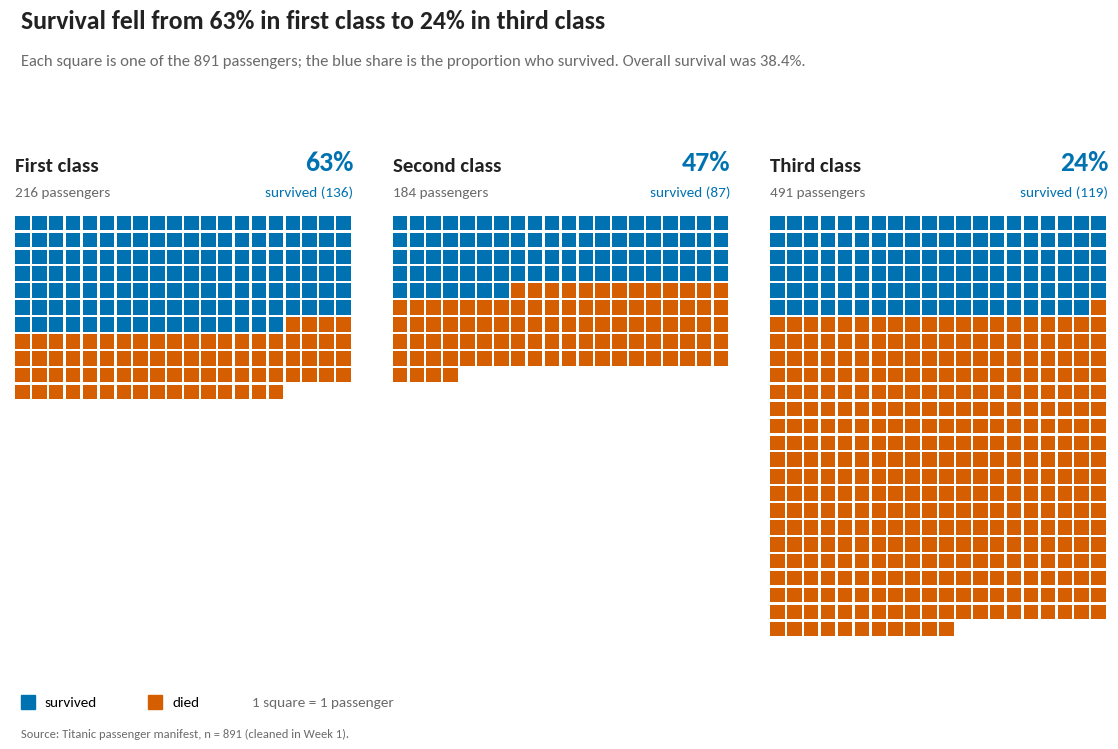

In [2]:
fig = plt.figure(figsize=(11.5, 7.6)); ncol = 20
gs = fig.add_gridspec(1, 3, left=0.03, right=0.985, top=0.80, bottom=0.10, wspace=0.10)
rates = {}
for i, cls in enumerate([1, 2, 3]):
    sub = d[d.Pclass == cls]; n = len(sub); k = int(sub.Survived.sum()); rates[cls] = (k, n)
    ax = fig.add_subplot(gs[0, i]); ax.set_aspect("equal"); ax.axis("off")
    for j in range(n):
        ax.add_patch(Rectangle((j % ncol, -(j // ncol)), 0.86, 0.86, color=SURV if j < k else DIED, lw=0))
    ax.set_xlim(-0.3, ncol); ax.set_ylim(-25.4, 4.6)
    ax.text(0, 3.3, CLS[cls], fontsize=15, fontweight="bold", color=INK, va="bottom")
    ax.text(0, 1.9, f"{n} passengers", fontsize=11, color=MUTED, va="bottom")
    ax.text(ncol, 3.3, f"{k/n:.0%}", fontsize=20, fontweight="bold", color=SURV, ha="right", va="bottom")
    ax.text(ncol, 1.9, f"survived ({k})", fontsize=11, color=SURV, ha="right", va="bottom")
fig.patches.extend([Rectangle((0.04, 0.052), 0.012, 0.018, transform=fig.transFigure, color=SURV), Rectangle((0.15, 0.052), 0.012, 0.018, transform=fig.transFigure, color=DIED)])
fig.text(0.060, 0.052, "survived", fontsize=11, va="bottom"); fig.text(0.171, 0.052, "died", fontsize=11, va="bottom"); fig.text(0.24, 0.052, "1 square = 1 passenger", fontsize=11, color=MUTED, va="bottom")
titled(fig, f"Survival fell from {rates[1][0]/rates[1][1]:.0%} in first class to {rates[3][0]/rates[3][1]:.0%} in third class",
       f"Each square is one of the {len(d)} passengers; the blue share is the proportion who survived. Overall survival was {d.Survived.mean():.1%}.", SRC)
R["fig1"] = {CLS[c]: {"survived": k, "n": n, "rate": k/n} for c, (k, n) in rates.items()}; R["overall"] = float(d.Survived.mean())
save(fig, "fig01_waffle_class")

## Act 2: The headline. How much did sex and class matter?
**Figure 2: slope chart.** Two lines, one per sex, across the three classes make the *interaction* visible at a glance: the lines are not parallel. Vertical bars are 95% Wilson confidence intervals, and sample sizes are printed so the reader can judge how much weight each point deserves.

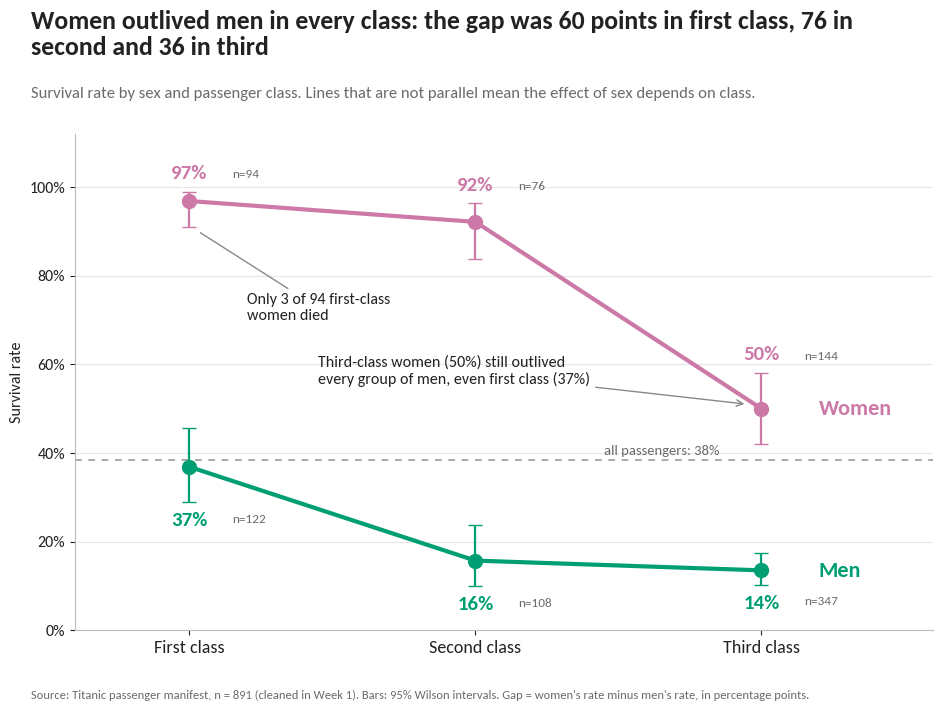

In [3]:
g = d.groupby(["Sex", "Pclass"]).Survived.agg(["sum", "count"]).reset_index(); g["rate"] = g["sum"] / g["count"]
g[["lo", "hi"]] = [wilson(k, n) for k, n in zip(g["sum"], g["count"])]
rate = {(r_.Sex, int(r_.Pclass)): r_.rate for _, r_ in g.iterrows()}; gap = {c: 100 * (rate[("Female", c)] - rate[("Male", c)]) for c in [1, 2, 3]}
fig, ax = plt.subplots(figsize=(11, 7.2)); fig.subplots_adjust(left=0.08, right=0.86, top=0.80, bottom=0.11)
for sex, col, up in [("Female", WOMEN, True), ("Male", MEN, False)]:
    s_ = g[g.Sex == sex].sort_values("Pclass")
    ax.errorbar(s_.Pclass, s_.rate, yerr=[s_.rate - s_.lo, s_.hi - s_.rate], color=col, lw=3, marker="o", ms=10, capsize=5, elinewidth=1.6, zorder=3)
    for _, r_ in s_.iterrows():
        y_ = r_.hi + 0.022 if up else r_.lo - 0.022
        ax.text(r_.Pclass, y_, f"{r_.rate:.0%}", color=col, fontsize=15, fontweight="bold", ha="center", va="bottom" if up else "top")
        ax.text(r_.Pclass + 0.15, y_ + (0.004 if up else -0.004), f"n={int(r_['count'])}", color=MUTED, fontsize=9.5, ha="left", va="bottom" if up else "top")
ax.axhline(d.Survived.mean(), color="#999999", ls=(0, (4, 4)), lw=1.2, zorder=1); ax.text(2.45, d.Survived.mean() + 0.012, f"all passengers: {d.Survived.mean():.0%}", color=MUTED, fontsize=10.5)
ax.text(3.2, rate[("Female", 3)], "Women", color=WOMEN, fontsize=16, fontweight="bold", va="center"); ax.text(3.2, rate[("Male", 3)], "Men", color=MEN, fontsize=16, fontweight="bold", va="center")
f1d = int(((d.Sex == "Female") & (d.Pclass == 1) & (d.Survived == 0)).sum()); f1n = int(((d.Sex == "Female") & (d.Pclass == 1)).sum())
ax.annotate(f"Only {f1d} of {f1n} first-class\nwomen died", xy=(1.03, 0.90), xytext=(1.2, 0.70), fontsize=11.5, color=INK, arrowprops=dict(arrowstyle="-", color="#888888", lw=1))
ax.annotate(f"Third-class women ({rate[('Female',3)]:.0%}) still outlived\nevery group of men, even first class ({rate[('Male',1)]:.0%})", xy=(2.95, rate[("Female", 3)] + 0.01), xytext=(1.45, 0.555), fontsize=11.5, color=INK, arrowprops=dict(arrowstyle="->", color="#888888", lw=1))
ax.set_xlim(0.6, 3.6); ax.set_ylim(0, 1.12); ax.set_xticks([1, 2, 3]); ax.set_xticklabels(list(CLS.values()), fontsize=13)
ax.yaxis.set_major_formatter(PercentFormatter(1)); ax.set_yticks([0, .2, .4, .6, .8, 1.0]); ax.set_ylabel("Survival rate"); ax.grid(axis="y", color=GRID, zorder=0)
titled(fig, f"Women outlived men in every class: the gap was {gap[1]:.0f} points in first class, {gap[2]:.0f} in second and {gap[3]:.0f} in third",
       "Survival rate by sex and passenger class. Lines that are not parallel mean the effect of sex depends on class.", SRC + " Bars: 95% Wilson intervals. Gap = women's rate minus men's rate, in percentage points.")
R["fig2"] = [{"sex": r_.Sex, "class": int(r_.Pclass), "rate": float(r_.rate), "k": int(r_["sum"]), "n": int(r_["count"])} for _, r_ in g.iterrows()]; R["fig2_gap_points"] = {int(k): float(v) for k, v in gap.items()}
save(fig, "fig02_slope_sex_class")

## Act 3: Age. Were children really first?
**Figure 3: smoothed survival curves.** Binning age hides the shape, so survival probability is estimated with a kernel smoother and a 95% bootstrap band (300 resamples). The strip below shows *how many passengers* the curve rests on, so the reader can see where it is trustworthy. Only the 714 recorded ages are used; imputed ages would add artificial structure.

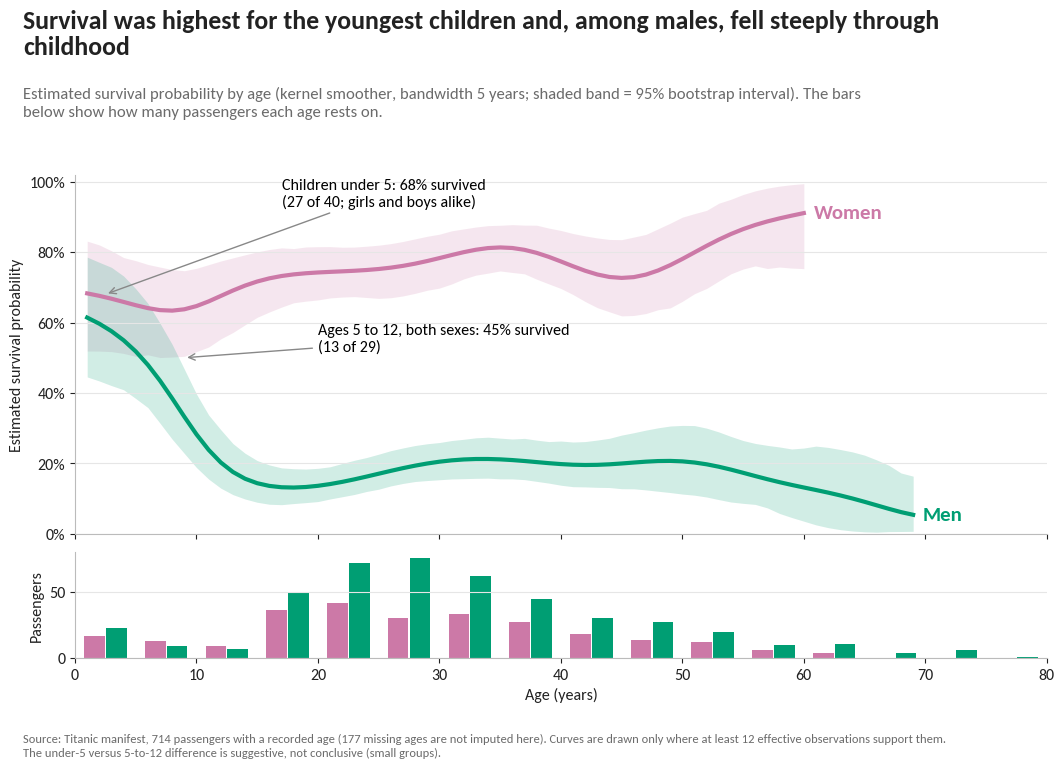

In [4]:
def nw(x, y, grid, bw=5.0):
    w = np.exp(-0.5 * ((grid[:, None] - x[None, :]) / bw) ** 2); return (w * y).sum(1) / w.sum(1), w.sum(1)
rng = np.random.default_rng(5); grid = np.arange(1, 76, 1.0); curves = {}
for sex in ["Female", "Male"]:
    s_ = real[real.Sex == sex]; x, y = s_.Age.values, s_.Survived.values
    est, eff = nw(x, y, grid); boots = np.array([nw(x[i], y[i], grid)[0] for i in (rng.integers(0, len(x), len(x)) for _ in range(300))])
    lo, hi = np.percentile(boots, [2.5, 97.5], axis=0); ok = eff >= 12; curves[sex] = (est, lo, hi, ok)
fig = plt.figure(figsize=(11.5, 7.8)); gs = fig.add_gridspec(2, 1, height_ratios=[3.4, 1], hspace=0.08, left=0.085, right=0.93, top=0.76, bottom=0.14)
ax = fig.add_subplot(gs[0]); axb = fig.add_subplot(gs[1], sharex=ax)
for sex, col, lab in [("Female", WOMEN, "Women"), ("Male", MEN, "Men")]:
    est, lo, hi, ok = curves[sex]; ax.fill_between(grid[ok], lo[ok], hi[ok], color=col, alpha=0.18, lw=0); ax.plot(grid[ok], est[ok], color=col, lw=3)
    ax.text(grid[ok][-1] + 0.8, est[ok][-1], lab, color=col, fontsize=15, fontweight="bold", va="center")
u5 = real[real.Age < 5]; k5, n5 = int(u5.Survived.sum()), len(u5); o512 = real[(real.Age >= 5) & (real.Age < 13)]; k512, n512 = int(o512.Survived.sum()), len(o512)
ax.annotate(f"Children under 5: {k5/n5:.0%} survived\n({k5} of {n5}; girls and boys alike)", xy=(2.5, 0.68), xytext=(17, 0.93), fontsize=11.5, arrowprops=dict(arrowstyle="->", color="#888888"))
ax.annotate(f"Ages 5 to 12, both sexes: {k512/n512:.0%} survived\n({k512} of {n512})", xy=(9, 0.50), xytext=(20, 0.52), fontsize=11.5, arrowprops=dict(arrowstyle="->", color="#888888"))
ax.set_ylim(0, 1.02); ax.yaxis.set_major_formatter(PercentFormatter(1)); ax.set_ylabel("Estimated survival probability"); ax.grid(axis="y", color=GRID); plt.setp(ax.get_xticklabels(), visible=False)
bins = np.arange(0, 85, 5)
for off, (sex, col) in zip([-0.9, 0.9], [("Female", WOMEN), ("Male", MEN)]):
    c_, _ = np.histogram(real[real.Sex == sex].Age, bins=bins); axb.bar(bins[:-1] + 2.5 + off, c_, width=1.7, color=col)
axb.set_ylabel("Passengers"); axb.set_xlabel("Age (years)"); axb.set_xlim(0, 80); axb.grid(axis="y", color=GRID)
titled(fig, "Survival was highest for the youngest children and, among males, fell steeply through childhood",
       "Estimated survival probability by age (kernel smoother, bandwidth 5 years; shaded band = 95% bootstrap interval). The bars below show how many passengers each age rests on.",
       "Source: Titanic manifest, 714 passengers with a recorded age (177 missing ages are not imputed here). Curves are drawn only where at least 12 effective observations support them. The under-5 versus 5-to-12 difference is suggestive, not conclusive (small groups).")
R["fig3"] = {"u5": [k5, n5], "5to12": [k512, n512], "u5_by_sex": real[real.Age < 5].groupby("Sex").Survived.agg(["sum", "count"]).astype(int).to_dict("index")}
save(fig, "fig03_age_curves")

## Act 4: Money. Did paying more buy survival?
**Figure 4: strip plot on a log scale.** Fares span from a few pounds to over two hundred, so a log axis is needed to see all three classes at once. Every passenger is a dot (no summarising away outliers); diamonds mark the medians. Dodging survivors and non-survivors within each class allows a direct comparison.

{'median_pp': {1: {'survived': 35.5, 'died': 35.0}, 2: {'survived': 13.0, 'died': 13.0}, 3: {'survived': 7.85055, 'died': 7.8542}}, 'mwu_p': {1: 0.39672457615600554, 2: 0.8127105134213866, 3: 0.9570895798078238}, 'median_ticket_total': {1: {'survived': 77.9583, 'died': 50.0}, 2: {'survived': 21.0, 'died': 13.0}, 3: {'survived': 8.5896, 'died': 8.05}}, 'zero_fare': [1, 15]}


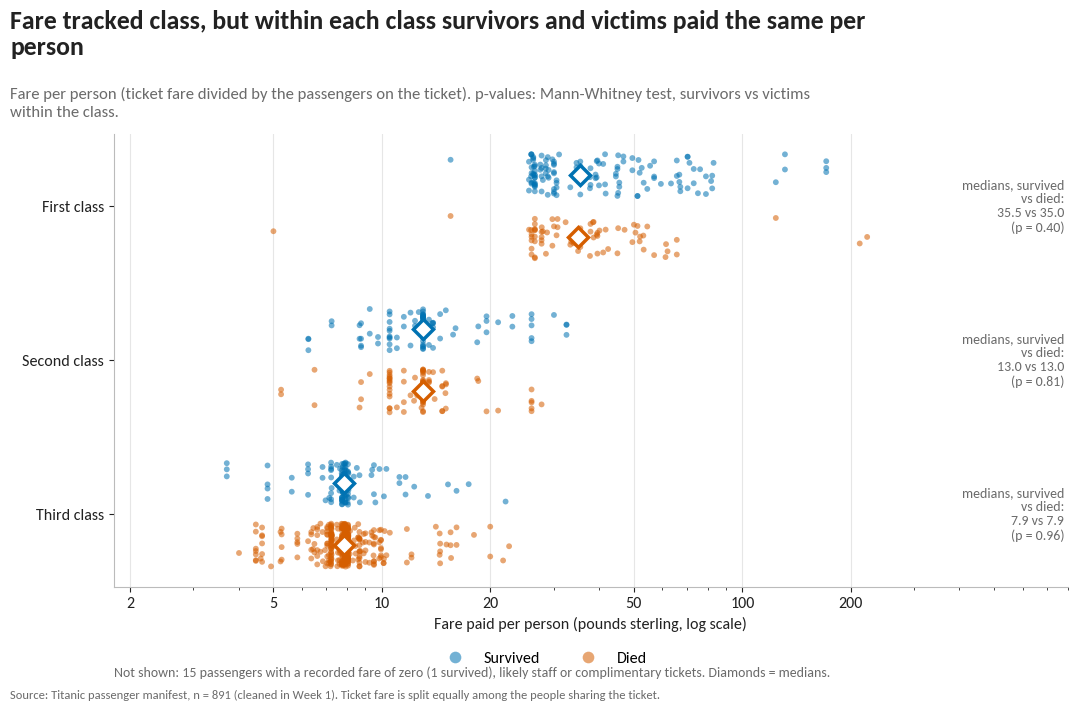

In [5]:
x = d[d.Fare_Zero == 0].copy(); x["Outcome"] = np.where(x.Survived == 1, "Survived", "Died"); x["Class"] = x.Pclass.map(CLS)
med = x.groupby(["Pclass", "Survived"]).Fare_Per_Person.median().unstack()
pvals = {c: float(stats.mannwhitneyu(x[(x.Pclass == c) & (x.Survived == 1)].Fare_Per_Person, x[(x.Pclass == c) & (x.Survived == 0)].Fare_Per_Person).pvalue) for c in [1, 2, 3]}
tot = d[d.Fare_Zero == 0].groupby(["Pclass", "Survived"]).Fare.median().unstack()
zero = d[d.Fare_Zero == 1]; zk, zn = int(zero.Survived.sum()), len(zero)
fig, ax = plt.subplots(figsize=(11.5, 7.2)); fig.subplots_adjust(left=0.13, right=0.96, top=0.80, bottom=0.17)
sns.stripplot(data=x, x="Fare_Per_Person", y="Class", hue="Outcome", order=list(CLS.values()), hue_order=["Survived", "Died"], palette={"Survived": SURV, "Died": DIED}, dodge=True, jitter=0.28, size=4.2, alpha=0.55, ax=ax, linewidth=0)
ax.set_xscale("log"); ax.set_xlim(1.8, 800); ax.set_xticks([2, 5, 10, 20, 50, 100, 200]); ax.set_xticklabels(["2", "5", "10", "20", "50", "100", "200"])
for i, c in enumerate([1, 2, 3]):
    for j, (s_, col) in enumerate([(1, SURV), (0, DIED)]):
        ax.plot(med.loc[c, s_], i + (-0.2 if j == 0 else 0.2), marker="D", ms=10, mfc="white", mec=col, mew=2.5, zorder=5)
    ax.text(780, i, f"medians, survived\nvs died:\n{med.loc[c,1]:.1f} vs {med.loc[c,0]:.1f}\n(p = {pvals[c]:.2f})", fontsize=10, color=MUTED, va="center", ha="right")
ax.set_xlabel("Fare paid per person (pounds sterling, log scale)"); ax.set_ylabel(""); ax.grid(axis="x", color=GRID)
ax.legend(title="", frameon=False, loc="upper center", ncol=2, bbox_to_anchor=(0.45, -0.11), markerscale=2)
fig.text(0.13, 0.045, f"Not shown: {zn} passengers with a recorded fare of zero ({zk} survived), likely staff or complimentary tickets. Diamonds = medians.", fontsize=10, color=MUTED)
titled(fig, "Fare tracked class, but within each class survivors and victims paid the same per person",
       "Fare per person (ticket fare divided by the passengers on the ticket). p-values: Mann-Whitney test, survivors vs victims within the class.",
       SRC + " Ticket fare is split equally among the people sharing the ticket.")
R["fig4"] = {"median_pp": {int(c): {"survived": float(med.loc[c, 1]), "died": float(med.loc[c, 0])} for c in [1, 2, 3]}, "mwu_p": pvals,
             "median_ticket_total": {int(c): {"survived": float(tot.loc[c, 1]), "died": float(tot.loc[c, 0])} for c in [1, 2, 3]}, "zero_fare": [zk, zn]}
print(R["fig4"]); save(fig, "fig04_fare_strip")

In [6]:
# Why did the TICKET fare (Week 2) differ by outcome while the per-person fare does not? Test whether survivors more often shared a ticket.
chk = []
for c in [1, 2, 3]:
    a_ = x[(x.Pclass == c) & (x.Survived == 1)]; b_ = x[(x.Pclass == c) & (x.Survived == 0)]
    chk.append({"class": c, "shared_ticket_survived": float((a_.Ticket_Size > 1).mean()), "shared_ticket_died": float((b_.Ticket_Size > 1).mean()),
                "ticket_size_p": float(stats.mannwhitneyu(a_.Ticket_Size, b_.Ticket_Size).pvalue), "total_fare_p": float(stats.mannwhitneyu(a_.Fare, b_.Fare).pvalue)})
R["fig4_tickets"] = chk; print(pd.DataFrame(chk).round(4))

   class  shared_ticket_survived  shared_ticket_died  ticket_size_p  \
0      1                  0.6618              0.3867         0.0003   
1      2                  0.4828              0.3516         0.1063   
2      3                  0.3898              0.2656         0.0514   

   total_fare_p  
0        0.0008  
1        0.0227  
2        0.1946  


**A check on an earlier result.** In Week 2 the *ticket* fare (the total printed for a ticket) was higher for survivors in first and second class. The figure shows that the *per-person* fare is the same for survivors and victims in every class (Mann-Whitney p = 0.40, 0.81, 0.96). The cell above tests the likely reason: in first class 66% of survivors but only 39% of victims were on a ticket shared with others (p = 0.0003), and a shared ticket carries a larger total. The same direction appears in second class (48% vs 35%) and third class (39% vs 27%) but is weaker and not conclusive there. The visualization therefore refines the earlier message: fare marks class, and the ticket-level gap mostly reflects who travelled in groups, not a separate advantage of paying more.

## Act 5: Hidden structure. Family and port
**Figure 5: lollipop plot with a split by sex.** Survival by family size looks like an inverted U. The right panel splits by sex to check whether this is simply because small families contained more women. **Figure 6: small multiples** place three views of the ports side by side (survival, class mix, sex mix) so the reader can see *why* the Cherbourg figure is higher.

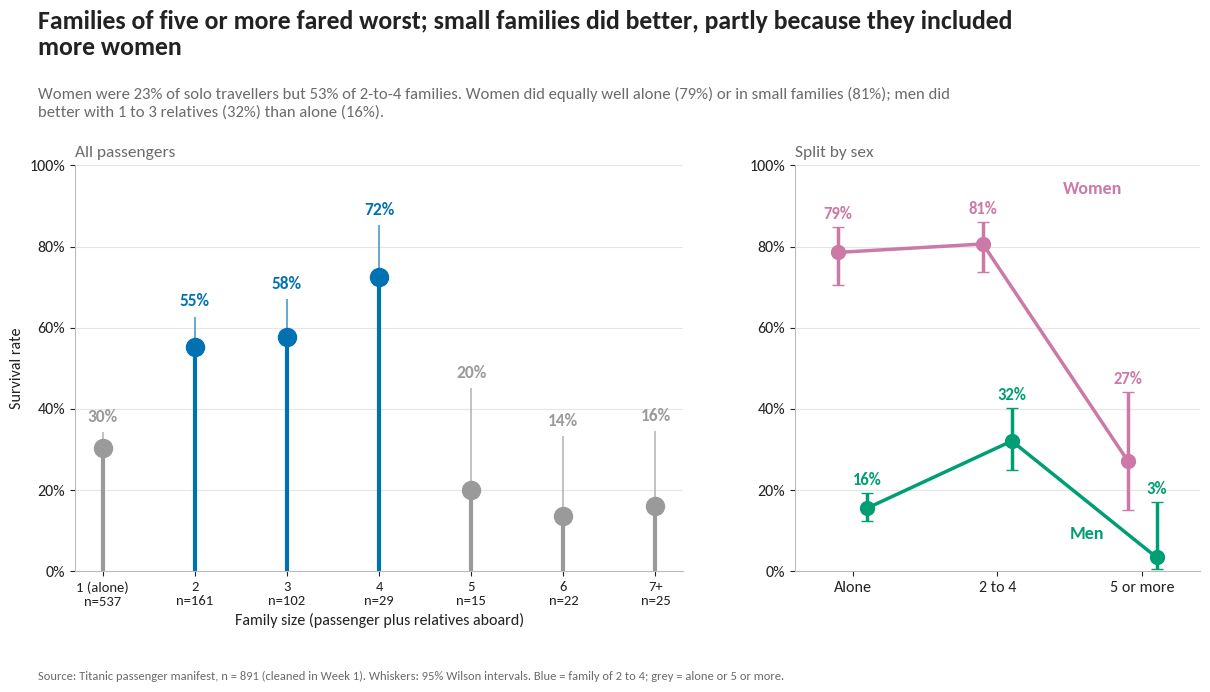

In [7]:
d["FS_grp"] = pd.cut(d.Family_Size, [0, 1, 2, 3, 4, 5, 6, 20], labels=["1 (alone)", "2", "3", "4", "5", "6", "7+"])
f = d.groupby("FS_grp", observed=True).Survived.agg(["sum", "count"]); f["rate"] = f["sum"] / f["count"]; f[["lo", "hi"]] = [wilson(k, n) for k, n in zip(f["sum"], f["count"])]
d["FS3"] = pd.cut(d.Family_Size, [0, 1, 4, 20], labels=["Alone", "2 to 4", "5 or more"])
f3 = d.groupby(["Sex", "FS3"], observed=True).Survived.agg(["sum", "count"]).reset_index(); f3["rate"] = f3["sum"] / f3["count"]; f3[["lo", "hi"]] = [wilson(k, n) for k, n in zip(f3["sum"], f3["count"])]
fig, ax = plt.subplots(1, 2, figsize=(12.5, 7), gridspec_kw={"width_ratios": [1.5, 1]}); fig.subplots_adjust(left=0.07, right=0.97, top=0.75, bottom=0.17, wspace=0.22)
a = ax[0]; xs = np.arange(len(f)); hl = [i for i, l in enumerate(f.index) if l in ["2", "3", "4"]]
for i, (idx, r_) in enumerate(f.iterrows()):
    col = SURV if i in hl else "#9A9A9A"; a.vlines(i, 0, r_.rate, color=col, lw=3); a.plot(i, r_.rate, "o", color=col, ms=13, zorder=3); a.vlines(i, r_.lo, r_.hi, color=col, lw=1.2, alpha=0.7)
    a.text(i, r_.hi + 0.025, f"{r_.rate:.0%}", ha="center", fontsize=12.5, fontweight="bold", color=col)
a.set_xticks(xs); a.set_xticklabels([f"{l}\nn={int(n)}" for l, n in zip(f.index, f["count"])], fontsize=10.5); a.set_xlabel("Family size (passenger plus relatives aboard)"); a.set_ylim(0, 1.0); a.yaxis.set_major_formatter(PercentFormatter(1)); a.set_ylabel("Survival rate"); a.grid(axis="y", color=GRID)
a.set_title("All passengers", loc="left", fontsize=12.5, color=MUTED)
b = ax[1]
for sex, col, off in [("Female", WOMEN, -0.1), ("Male", MEN, 0.1)]:
    s_ = f3[f3.Sex == sex]; xx = np.arange(3) + off
    b.errorbar(xx, s_.rate, yerr=[s_.rate - s_.lo, s_.hi - s_.rate], color=col, marker="o", ms=10, lw=2.5, capsize=4)
    for xi, (_, r_) in zip(xx, s_.iterrows()): b.text(xi, r_.hi + 0.02, f"{r_.rate:.0%}", color=col, fontsize=12, fontweight="bold", ha="center")
b.text(1.45, 0.93, "Women", color=WOMEN, fontsize=13, fontweight="bold"); b.text(1.5, 0.08, "Men", color=MEN, fontsize=13, fontweight="bold")
b.set_xticks(range(3)); b.set_xticklabels(["Alone", "2 to 4", "5 or more"]); b.set_ylim(0, 1.0); b.yaxis.set_major_formatter(PercentFormatter(1)); b.grid(axis="y", color=GRID); b.set_title("Split by sex", loc="left", fontsize=12.5, color=MUTED); b.set_xlim(-0.4, 2.4)
share = d.groupby("FS3", observed=True).apply(lambda g_: (g_.Sex == "Female").mean(), include_groups=False)
mk = f3.set_index(["Sex", "FS3"]).rate
titled(fig, "Families of five or more fared worst; small families did better, partly because they included more women",
       f"Women were {share['Alone']:.0%} of solo travellers but {share['2 to 4']:.0%} of 2-to-4 families. Women did equally well alone ({mk[('Female','Alone')]:.0%}) or in small families ({mk[('Female','2 to 4')]:.0%}); men did better with 1 to 3 relatives ({mk[('Male','2 to 4')]:.0%}) than alone ({mk[('Male','Alone')]:.0%}).",
       SRC + " Whiskers: 95% Wilson intervals. Blue = family of 2 to 4; grey = alone or 5 or more.")
R["fig5"] = {"by_size": {str(k): {"rate": float(v.rate), "n": int(v["count"])} for k, v in f.iterrows()}, "by_sex_group": [{"sex": r_.Sex, "grp": str(r_.FS3), "rate": float(r_.rate), "n": int(r_["count"])} for _, r_ in f3.iterrows()], "women_share": {str(k): float(v) for k, v in share.items()}}
save(fig, "fig05_family_size")

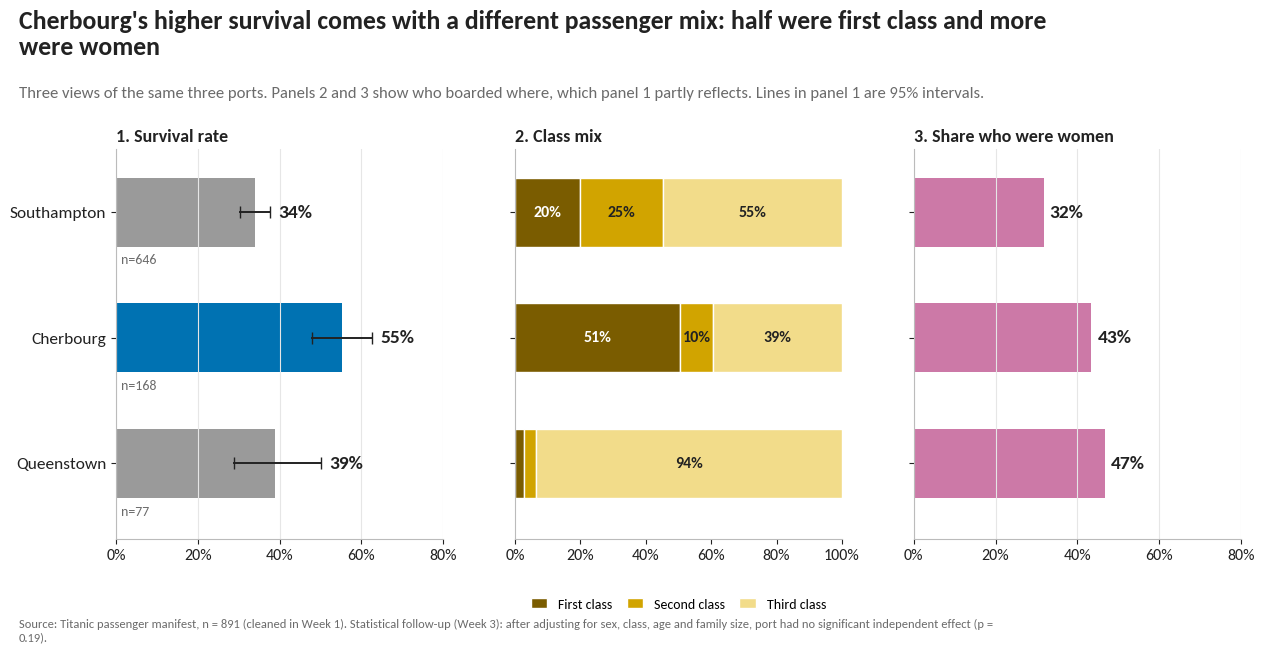

In [8]:
ports = ["Southampton", "Cherbourg", "Queenstown"]; pt = d.groupby("Embarked").Survived.agg(["sum", "count"]); pt["rate"] = pt["sum"] / pt["count"]; pt[["lo", "hi"]] = [wilson(k, n) for k, n in zip(pt["sum"], pt["count"])]
mix = pd.crosstab(d.Embarked, d.Pclass, normalize="index").reindex(ports); wom = d.groupby("Embarked").apply(lambda g_: (g_.Sex == "Female").mean(), include_groups=False).reindex(ports)
fig, ax = plt.subplots(1, 3, figsize=(13, 6.6)); fig.subplots_adjust(left=0.115, right=0.98, top=0.76, bottom=0.17, wspace=0.22)
a = ax[0]; yy = np.arange(3)[::-1]
for y_, p_ in zip(yy, ports):
    r_ = pt.loc[p_]; a.barh(y_, r_.rate, color=SURV if p_ == "Cherbourg" else "#9A9A9A", height=0.55); a.plot([r_.lo, r_.hi], [y_, y_], color=INK, lw=1.4, marker="|", ms=9)
    a.text(0.012, y_ - 0.38, f"n={int(r_['count'])}", color=MUTED, va="center", fontsize=10); a.text(r_.hi + 0.02, y_, f"{r_.rate:.0%}", va="center", fontsize=14, fontweight="bold", color=INK)
a.set_yticks(yy); a.set_yticklabels(ports, fontsize=12.5); a.set_ylim(-0.6, 2.5); a.set_xlim(0, 0.8); a.xaxis.set_major_formatter(PercentFormatter(1)); a.set_title("1. Survival rate", loc="left", fontsize=13, color=INK, fontweight="bold"); a.grid(axis="x", color=GRID)
b = ax[1]; left = np.zeros(3)
for cls in [1, 2, 3]:
    v = mix[cls].values; b.barh(yy, v, left=left, color=CLASS_COL[cls], height=0.55, edgecolor="white", label=CLS[cls])
    for y_, l_, v_ in zip(yy, left, v):
        if v_ > 0.06: b.text(l_ + v_ / 2, y_, f"{v_:.0%}", ha="center", va="center", fontsize=11.5, fontweight="bold", color="white" if cls == 1 else INK)
    left += v
b.set_yticks(yy); b.set_yticklabels([]); b.set_ylim(-0.6, 2.5); b.set_xlim(0, 1); b.xaxis.set_major_formatter(PercentFormatter(1)); b.set_title("2. Class mix", loc="left", fontsize=13, color=INK, fontweight="bold")
b.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3, frameon=False, fontsize=10, handlelength=1.2, columnspacing=1.0)
c_ = ax[2]
for y_, p_ in zip(yy, ports):
    c_.barh(y_, wom[p_], color=WOMEN, height=0.55); c_.text(wom[p_] + 0.015, y_, f"{wom[p_]:.0%}", va="center", fontsize=14, fontweight="bold", color=INK)
c_.set_yticks(yy); c_.set_yticklabels([]); c_.set_ylim(-0.6, 2.5); c_.set_xlim(0, 0.8); c_.xaxis.set_major_formatter(PercentFormatter(1)); c_.set_title("3. Share who were women", loc="left", fontsize=13, color=INK, fontweight="bold"); c_.grid(axis="x", color=GRID)
titled(fig, "Cherbourg's higher survival comes with a different passenger mix: half were first class and more were women",
       "Three views of the same three ports. Panels 2 and 3 show who boarded where, which panel 1 partly reflects. Lines in panel 1 are 95% intervals.",
       SRC + " Statistical follow-up (Week 3): after adjusting for sex, class, age and family size, port had no significant independent effect (p = 0.19).")
R["fig6"] = {"surv": {p_: float(pt.loc[p_, "rate"]) for p_ in ports}, "first_class_share": {p_: float(mix.loc[p_, 1]) for p_ in ports}, "women_share": {p_: float(wom[p_]) for p_ in ports}, "n": {p_: int(pt.loc[p_, "count"]) for p_ in ports}}
save(fig, "fig06_ports_small_multiples")

## Act 6: A peculiarity. What does the missing data tell us?
**Figure 7: annotated heat map.** Missing values are not random, and showing *where* they occur is a finding in itself. Colour intensity encodes the share of values missing in each group; the numbers make exact reading possible.

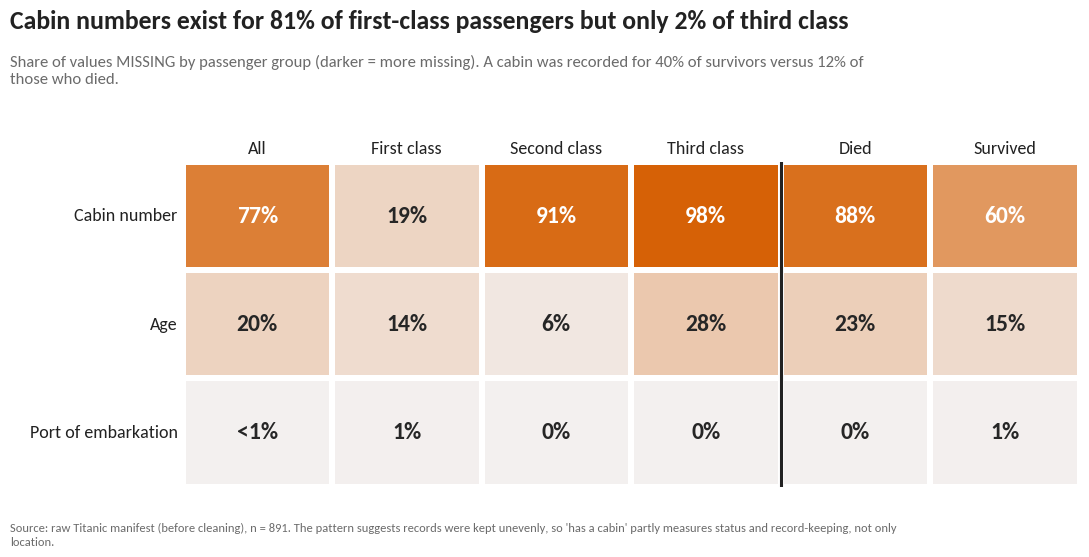

In [9]:
raw["Class"] = raw.Pclass.map(CLS); raw["Outcome"] = np.where(raw.Survived == 1, "Survived", "Died")
cols = [("All", lambda r_: r_), ("First class", lambda r_: r_[r_.Pclass == 1]), ("Second class", lambda r_: r_[r_.Pclass == 2]), ("Third class", lambda r_: r_[r_.Pclass == 3]), ("Died", lambda r_: r_[r_.Survived == 0]), ("Survived", lambda r_: r_[r_.Survived == 1])]
rows = [("Cabin number", "Cabin"), ("Age", "Age"), ("Port of embarkation", "Embarked")]
M_ = pd.DataFrame({lab: {rl: f(raw)[rc].isna().mean() for rl, rc in rows} for lab, f in cols})
fig, ax = plt.subplots(figsize=(11.5, 5.6)); fig.subplots_adjust(left=0.19, right=0.97, top=0.70, bottom=0.12)
sns.heatmap(M_, annot=M_.map(lambda v: "<1%" if 0 < v < 0.005 else f"{v:.0%}"), fmt="", cmap=sns.light_palette(DIED, as_cmap=True), vmin=0, vmax=1, cbar=False, linewidths=3, linecolor="white", annot_kws={"fontsize": 17, "fontweight": "bold"}, ax=ax)
ax.set_ylabel(""); ax.set_xlabel(""); ax.xaxis.tick_top(); ax.tick_params(length=0, labelsize=13); plt.setp(ax.get_yticklabels(), rotation=0)
ax.axvline(4, color=INK, lw=2.2)
cab_s = raw[raw.Survived == 1].Cabin.notna().mean(); cab_d = raw[raw.Survived == 0].Cabin.notna().mean(); cab1 = raw[raw.Pclass == 1].Cabin.notna().mean(); cab3 = raw[raw.Pclass == 3].Cabin.notna().mean()
titled(fig, f"Cabin numbers exist for {cab1:.0%} of first-class passengers but only {cab3:.0%} of third class",
       f"Share of values MISSING by passenger group (darker = more missing). A cabin was recorded for {cab_s:.0%} of survivors versus {cab_d:.0%} of those who died.",
       "Source: raw Titanic manifest (before cleaning), n = 891. The pattern suggests records were kept unevenly, so 'has a cabin' partly measures status and record-keeping, not only location.")
R["fig7"] = {"missing": {k: {c: float(v) for c, v in M_[k].items()} for k in M_.columns}, "cabin_recorded": {"first": float(cab1), "third": float(cab3), "survived": float(cab_s), "died": float(cab_d)}}
save(fig, "fig07_missingness_heatmap")

## Act 7: Prediction. Can a model reproduce the pattern, and how sure are we?
**Figure 8: model versus data.** A logistic regression (the Week 3 specification without port) is fitted and its predictions drawn as lines, with the *observed* survival rates in age bands shown as dots. If the model is sound, the dots follow the lines. **Figure 9: forest plot** compares the Week 4 machine-learning models with their uncertainty, so the reader can see that differences between them are smaller than the noise.

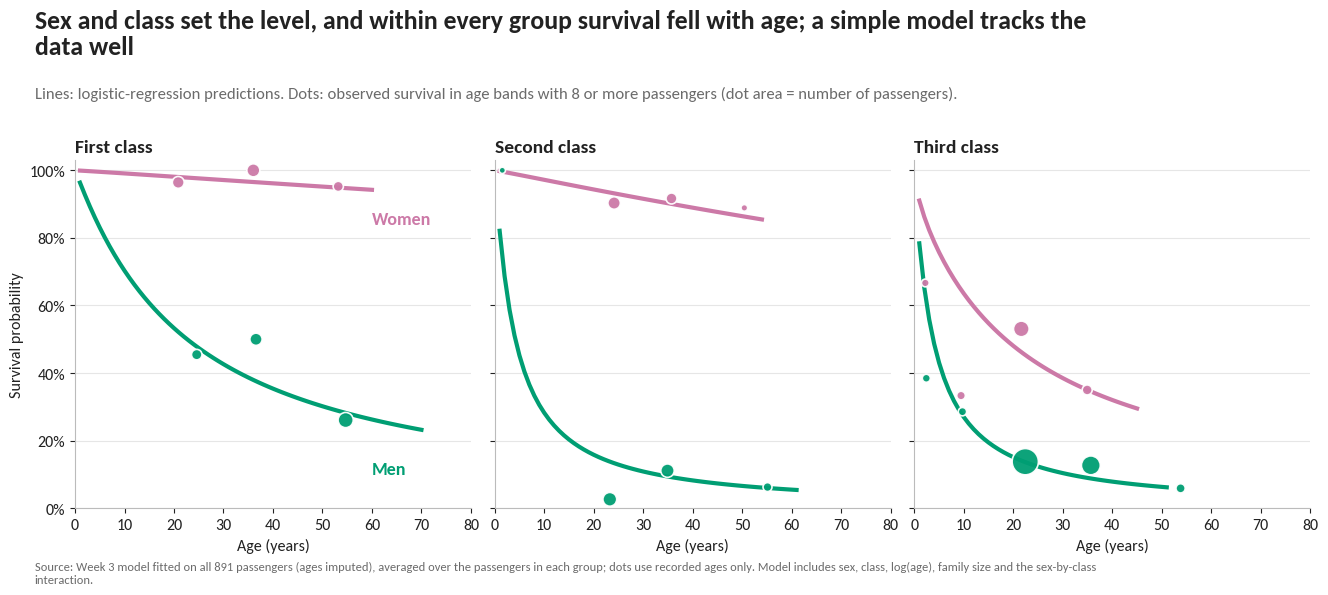

In [10]:
FSM = d.Family_Size.mean()
def design(df_, age=None):
    a = df_.Age.values if age is None else np.full(len(df_), age)
    X = pd.DataFrame({"Female": (df_.Sex == "Female").astype(int).values, "P2": (df_.Pclass == 2).astype(int).values, "P3": (df_.Pclass == 3).astype(int).values, "LA": np.log(a), "FS": (df_.Family_Size - FSM).values})
    X["FS2"] = X.FS ** 2; X["F_P2"] = X.Female * X.P2; X["F_P3"] = X.Female * X.P3; return X
lr = LogisticRegression(penalty=None, max_iter=20000).fit(design(d), d.Survived)
ages = np.arange(1, 71); edges = [0, 5, 15, 30, 45, 90]
fig, ax = plt.subplots(1, 3, figsize=(13.5, 6), sharey=True); fig.subplots_adjust(left=0.07, right=0.985, top=0.72, bottom=0.14, wspace=0.06)
dots = []
for i, cls in enumerate([1, 2, 3]):
    a = ax[i]
    for sex, col, lab in [("Female", WOMEN, "Women"), ("Male", MEN, "Men")]:
        grp = d[(d.Pclass == cls) & (d.Sex == sex)]; xmax = grp.Age.quantile(0.98)
        a_ok = ages[ages <= xmax]; pr = [lr.predict_proba(design(grp, age=v))[:, 1].mean() for v in a_ok]; a.plot(a_ok, pr, color=col, lw=3)
        rg = real[(real.Pclass == cls) & (real.Sex == sex)].copy(); rg["bin"] = pd.cut(rg.Age, edges, right=False)
        s = rg.groupby("bin", observed=True).agg(age=("Age", "mean"), rate=("Survived", "mean"), n=("Survived", "size")); s = s[s.n >= 8]
        a.scatter(s.age, s.rate, s=s.n * 2.6, color=col, edgecolor="white", linewidth=1.2, zorder=4, alpha=0.95)
        for _, r_ in s.iterrows(): dots.append({"class": cls, "sex": sex, "age": float(r_.age), "rate": float(r_.rate), "n": int(r_.n)})
    a.set_title(CLS[cls], loc="left", fontsize=14, fontweight="bold", color=INK); a.set_xlim(0, 80); a.set_ylim(0, 1.03); a.set_xlabel("Age (years)"); a.grid(axis="y", color=GRID)
    if i == 0: a.set_ylabel("Survival probability"); a.yaxis.set_major_formatter(PercentFormatter(1)); a.text(60, 0.84, "Women", color=WOMEN, fontsize=13, fontweight="bold"); a.text(60, 0.10, "Men", color=MEN, fontsize=13, fontweight="bold")
titled(fig, "Sex and class set the level, and within every group survival fell with age; a simple model tracks the data well",
       "Lines: logistic-regression predictions. Dots: observed survival in age bands with 8 or more passengers (dot area = number of passengers).",
       "Source: Week 3 model fitted on all 891 passengers (ages imputed), averaged over the passengers in each group; dots use recorded ages only. Model includes sex, class, log(age), family size and the sex-by-class interaction.")
R["fig8_dots"] = dots
save(fig, "fig08_model_vs_data")

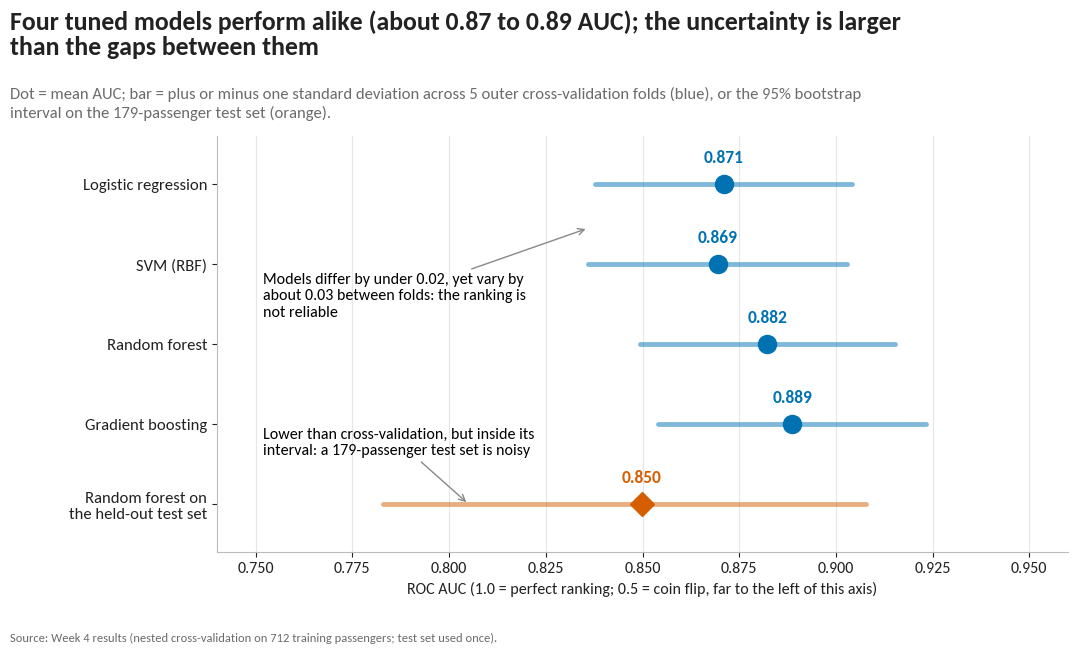

In [11]:
W4 = json.load(open("w4_results.json")); nest = {m["model"]: m for m in W4["nested"]}
order = ["Logistic regression", "SVM (RBF)", "Random forest", "Gradient boosting"]
fig, ax = plt.subplots(figsize=(11.5, 6.6)); fig.subplots_adjust(left=0.22, right=0.96, top=0.78, bottom=0.15)
yy = np.arange(len(order) + 1)[::-1]
for y_, m in zip(yy[:-1], order):
    mu, sd = nest[m]["nested_AUC"], nest[m]["nested_AUC_sd"]; ax.plot([mu - sd, mu + sd], [y_, y_], color=SURV, lw=3.5, alpha=0.5, solid_capstyle="round"); ax.plot(mu, y_, "o", color=SURV, ms=13, zorder=4)
    ax.text(mu, y_ + 0.27, f"{mu:.3f}", ha="center", fontsize=12.5, fontweight="bold", color=SURV)
tci = W4["test_ci"]["auc"]; tau = W4["test_05"]["auc"]; ax.plot(tci, [yy[-1]] * 2, color=DIED, lw=3.5, alpha=0.5, solid_capstyle="round"); ax.plot(tau, yy[-1], "D", color=DIED, ms=12, zorder=4); ax.text(tau, yy[-1] + 0.27, f"{tau:.3f}", ha="center", fontsize=12.5, fontweight="bold", color=DIED)
ax.set_yticks(yy); ax.set_yticklabels(order + ["Random forest on\nthe held-out test set"], fontsize=12); ax.set_xlim(0.74, 0.96); ax.set_ylim(-0.6, 4.6); ax.set_xlabel("ROC AUC (1.0 = perfect ranking; 0.5 = coin flip, far to the left of this axis)"); ax.grid(axis="x", color=GRID)
ax.annotate("Models differ by under 0.02, yet vary by\nabout 0.03 between folds: the ranking is\nnot reliable", xy=(0.836, 3.45), xytext=(0.752, 2.35), fontsize=11.5, arrowprops=dict(arrowstyle="->", color="#888888"))
ax.annotate("Lower than cross-validation, but inside its\ninterval: a 179-passenger test set is noisy", xy=(0.805, 0.0), xytext=(0.752, 0.62), fontsize=11.5, arrowprops=dict(arrowstyle="->", color="#888888"))
titled(fig, "Four tuned models perform alike (about 0.87 to 0.89 AUC); the uncertainty is larger than the gaps between them",
       "Dot = mean AUC; bar = plus or minus one standard deviation across 5 outer cross-validation folds (blue), or the 95% bootstrap interval on the 179-passenger test set (orange).",
       "Source: Week 4 results (nested cross-validation on 712 training passengers; test set used once).")
R["fig9"] = {"nested": {m: [nest[m]["nested_AUC"], nest[m]["nested_AUC_sd"]] for m in order}, "test_auc": tau, "test_ci": tci}
save(fig, "fig09_model_forest")

## Act 8: Summary. What should the reader remember?
**Figure 10: one-page summary graphic.** Big numbers for the headline facts, one annotated heat map for the central pattern (sex by class), and three plain-language takeaways. This is the figure designed to be shared on its own.

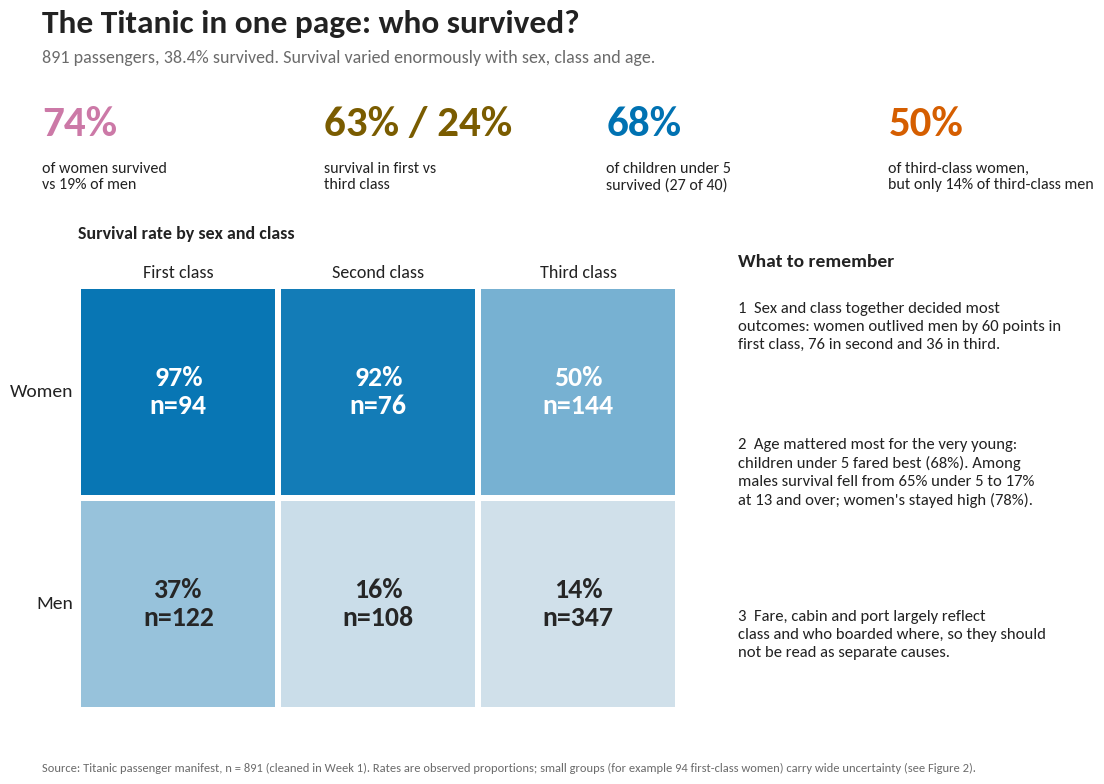

In [12]:
fig = plt.figure(figsize=(12, 8)); fig.subplots_adjust(left=0.05, right=0.97, top=0.94, bottom=0.05)
fig.text(0.04, 0.965, "The Titanic in one page: who survived?", fontsize=24, fontweight="bold", va="top", color=INK)
fig.text(0.04, 0.915, f"{len(d)} passengers, {d.Survived.mean():.1%} survived. Survival varied enormously with sex, class and age.", fontsize=13, va="top", color=MUTED)
wom = d[d.Sex == "Female"].Survived.mean(); men = d[d.Sex == "Male"].Survived.mean(); k3 = real[real.Age < 5]
big = [(f"{wom:.0%}", f"of women survived\nvs {men:.0%} of men", WOMEN), (f"{d[d.Pclass==1].Survived.mean():.0%} / {d[d.Pclass==3].Survived.mean():.0%}", "survival in first vs\nthird class", "#7A5C00"), (f"{k3.Survived.mean():.0%}", f"of children under 5\nsurvived ({int(k3.Survived.sum())} of {len(k3)})", SURV), (f"{d[(d.Sex=='Female')&(d.Pclass==3)].Survived.mean():.0%}", f"of third-class women,\nbut only {d[(d.Sex=='Male')&(d.Pclass==3)].Survived.mean():.0%} of third-class men", DIED)]
for i, (num, lab, col) in enumerate(big):
    x0 = 0.04 + i * 0.235; fig.text(x0, 0.845, num, fontsize=31, fontweight="bold", color=col, va="top"); fig.text(x0, 0.775, lab, fontsize=11.5, color=INK, va="top")
ax = fig.add_axes([0.07, 0.09, 0.50, 0.53]); pt_ = d.pivot_table(index="Sex", columns="Pclass", values="Survived", aggfunc="mean").loc[["Female", "Male"]]
cnt = d.pivot_table(index="Sex", columns="Pclass", values="Survived", aggfunc="count").loc[["Female", "Male"]]
sns.heatmap(pt_, annot=np.array([[f"{pt_.iloc[i,j]:.0%}\nn={int(cnt.iloc[i,j])}" for j in range(3)] for i in range(2)]), fmt="", cmap=sns.light_palette(SURV, as_cmap=True), vmin=0, vmax=1, cbar=False, linewidths=4, linecolor="white", annot_kws={"fontsize": 20, "fontweight": "bold"}, ax=ax)
ax.set_xticklabels(["First class", "Second class", "Third class"], fontsize=13); ax.set_yticklabels(["Women", "Men"], rotation=0, fontsize=14); ax.set_xlabel(""); ax.set_ylabel(""); ax.xaxis.tick_top(); ax.tick_params(length=0)
fig.text(0.07, 0.675, "Survival rate by sex and class", fontsize=13, fontweight="bold", color=INK, va="bottom")
gp = {c: 100 * (d[(d.Sex == "Female") & (d.Pclass == c)].Survived.mean() - d[(d.Sex == "Male") & (d.Pclass == c)].Survived.mean()) for c in [1, 2, 3]}
m_u5 = real[(real.Sex == "Male") & (real.Age < 5)].Survived.mean(); m_13 = real[(real.Sex == "Male") & (real.Age >= 13)].Survived.mean(); w_13 = real[(real.Sex == "Female") & (real.Age >= 13)].Survived.mean()
take = [f"1  Sex and class together decided most outcomes: women outlived men by {gp[1]:.0f} points in first class, {gp[2]:.0f} in second and {gp[3]:.0f} in third.",
        f"2  Age mattered most for the very young: children under 5 fared best ({k3.Survived.mean():.0%}). Among males survival fell from {m_u5:.0%} under 5 to {m_13:.0%} at 13 and over; women's stayed high ({w_13:.0%}).",
        "3  Fare, cabin and port largely reflect class and who boarded where, so they should not be read as separate causes."]
fig.text(0.62, 0.66, "What to remember", fontsize=14, fontweight="bold", color=INK, va="top")
import textwrap
yv = 0.60
for t in take:
    w = textwrap.fill(t, 44); fig.text(0.62, yv, w, fontsize=12, color=INK, va="top", linespacing=1.35); yv -= 0.045 * (w.count("\n") + 1) + 0.035
fig.text(0.04, 0.012, SRC + " Rates are observed proportions; small groups (for example 94 first-class women) carry wide uncertainty (see Figure 2).", fontsize=9, color=MUTED)
save(fig, "fig10_summary")

## Explore: interactive dashboard (Plotly)
Static charts tell one story; an interactive page lets the reader ask their own questions. The HTML file has (1) a **Sankey diagram** following all 891 passengers from sex, to sex-by-class group, to outcome (hover for exact counts and rates), and (2) a **survival-rate explorer** with a dropdown to switch the grouping variable. Both show confidence intervals and counts on hover.

In [13]:
import plotly.graph_objects as go
# --- Sankey: Sex -> Sex x Class -> Outcome (paths are exact, nothing is aggregated across groups)
sexes = ["Women", "Men"]; classes = ["First", "Second", "Third"]
nodes = sexes + [f"{s} - {c}" for s in sexes for c in classes] + ["Survived", "Died"]
idx = {n: i for i, n in enumerate(nodes)}; src, tgt, val, colr, hov = [], [], [], [], []
for s_lab, s_val in [("Women", "Female"), ("Men", "Male")]:
    for c_i, c_lab in enumerate(classes, start=1):
        sub = d[(d.Sex == s_val) & (d.Pclass == c_i)]; n = len(sub); k = int(sub.Survived.sum()); mid = f"{s_lab} - {c_lab}"
        src += [idx[s_lab], idx[mid], idx[mid]]; tgt += [idx[mid], idx["Survived"], idx["Died"]]; val += [n, k, n - k]
        colr += ["rgba(150,150,150,0.35)", "rgba(0,114,178,0.55)", "rgba(213,94,0,0.55)"]
        hov += [f"{n} {s_lab.lower()} travelled {c_lab.lower()} class", f"{k} of {n} survived ({k/n:.0%})", f"{n-k} of {n} died ({(n-k)/n:.0%})"]
node_cols = ["#CC79A7", "#009E73"] + ["#7A5C00", "#D1A400", "#B8A04A"] * 2 + ["#0072B2", "#D55E00"]
sank = go.Figure(go.Sankey(arrangement="snap", node=dict(label=nodes, color=node_cols, pad=18, thickness=22, line=dict(color="white", width=0.5)),
        link=dict(source=src, target=tgt, value=val, color=colr, customdata=hov, hovertemplate="%{customdata}<extra></extra>")))
sank.update_layout(title=dict(text="<b>Follow every passenger: sex, then class, then outcome</b><br><sup>Link width = number of passengers. Hover over a flow for counts.</sup>", x=0.01), font=dict(size=13), height=560, margin=dict(l=20, r=20, t=90, b=20))
# --- Explorer: survival rate by chosen variable (dropdown)
d["Age group"] = pd.cut(real.Age.reindex(d.index), [0, 5, 12, 18, 35, 60, 100], right=False, labels=["Under 5", "5-12", "13-17", "18-34", "35-59", "60+"]).astype(object).fillna("Age not recorded")
d["Family"] = d.FS3.astype(str)
variables = {"Sex": "Sex", "Passenger class": "Pclass", "Port": "Embarked", "Age group": "Age group", "Family size": "Family", "Title": "Title", "Cabin recorded": "Has_Cabin"}
exp = go.Figure(); buttons = []
for vi, (lab, col) in enumerate(variables.items()):
    t = d.groupby(col).Survived.agg(["sum", "count"]).reset_index(); t["rate"] = t["sum"] / t["count"]; t[["lo", "hi"]] = [wilson(k, n) for k, n in zip(t["sum"], t["count"])]
    t = t.sort_values("rate", ascending=False) if lab in ("Title",) else t
    cats = t[col].astype(str).tolist()
    if lab == "Cabin recorded": cats = ["Yes" if c == "1" else "No" for c in cats]
    exp.add_trace(go.Bar(x=cats, y=t.rate, marker_color="#0072B2", visible=(vi == 0), error_y=dict(type="data", symmetric=False, array=(t.hi - t.rate), arrayminus=(t.rate - t.lo), color="#444444"),
        customdata=np.c_[t["sum"], t["count"], t.lo, t.hi], hovertemplate="<b>%{x}</b><br>Survival rate: %{y:.1%}<br>%{customdata[0]} of %{customdata[1]} survived<br>95% CI: %{customdata[2]:.0%} to %{customdata[3]:.0%}<extra></extra>", name=lab))
    vis = [False] * len(variables); vis[vi] = True; buttons.append(dict(label=lab, method="update", args=[{"visible": vis}, {"xaxis.title.text": lab}]))
exp.add_hline(y=d.Survived.mean(), line_dash="dash", line_color="#888888", annotation_text=f"overall {d.Survived.mean():.0%}", annotation_position="top right")
exp.update_layout(updatemenus=[dict(buttons=buttons, direction="down", x=0.01, y=1.16, xanchor="left", showactive=True)], yaxis=dict(tickformat=".0%", range=[0, 1.05], title="Survival rate", gridcolor="#E6E6E6"), xaxis=dict(title="Sex"),
        title=dict(text="<b>Survival-rate explorer</b><br><sup>Choose a grouping from the menu. Bars: observed rate; whiskers: 95% Wilson interval.</sup>", x=0.01, y=0.97), plot_bgcolor="white", font=dict(size=13), height=520, margin=dict(l=60, r=20, t=110, b=60))
html = f"""<!DOCTYPE html><html lang="en"><head><meta charset="utf-8"><meta name="viewport" content="width=device-width, initial-scale=1"><title>Titanic survival: interactive dashboard</title>
<style>body{{font-family:Calibri,Carlito,Arial,sans-serif;max-width:1100px;margin:0 auto;padding:24px;color:#222}}h1{{margin-bottom:4px}}p.lead{{color:#555;margin-top:0}}.card{{border:1px solid #e3e3e3;border-radius:10px;padding:8px;margin:18px 0}}footer{{color:#777;font-size:13px}}</style></head><body>
<h1>Who survived the Titanic?</h1><p class="lead">An interactive companion to the Week 5 visual story. {len(d)} passengers; {d.Survived.mean():.1%} survived.</p>
<div class="card">{sank.to_html(full_html=False, include_plotlyjs=True, div_id="sankey")}</div><div class="card">{exp.to_html(full_html=False, include_plotlyjs=False, div_id="explorer")}</div>
<footer>Source: Titanic passenger manifest (cleaned in Week 1). Ages in the age-group view use recorded ages only; passengers without a recorded age appear as "Age not recorded".</footer></body></html>"""
open("figures/titanic_interactive_dashboard.html", "w", encoding="utf-8").write(html); print("HTML bytes:", len(html))
R["explorer_groups"] = {lab: d.groupby(col).Survived.size().to_dict() for lab, col in variables.items() if lab in ("Sex", "Passenger class", "Port")}

HTML bytes: 4840977


In [14]:
json.dump(R, open("w5_results.json", "w"), indent=1, default=str); print("saved", list(R))

saved ['fig1', 'overall', 'fig2', 'fig2_gap_points', 'fig3', 'fig4', 'fig4_tickets', 'fig5', 'fig6', 'fig7', 'fig8_dots', 'fig9', 'explorer_groups']
